# Circular-encounter energy sweep


Runs McFACTS with the **analytical** gas-hardening (gas drag) model for a range of
$\mu_{\rm circ}$, the mean fractional energy exchanged in encounters with circular orbiters
(`mu_circ_encounter`). Every run is 500 active timesteps long. The population is saved
every 100 timesteps, plus every 25 timesteps (0.25 Myr) over the first Myr, so one run gives
snapshots of the same galaxies at 0.25, 0.5, 0.75, 1, 2, 3, 4 and 5 Myr.

Each figure is a grid with one row per $\mu_{\rm circ}$ and one column per snapshot, time
increasing left to right. Each standard plot in `mcfacts.fiducial_plots` gets two grids: one
for 1–5 Myr and one for the first Myr (0.25–1 Myr).

**Layout**

1. Setup: imports and parameters (edit the sweep here)
2. Configurations: one `SettingsManager` per sweep value
3. Simulation: timeline, checkpoint recorder, run loop (skips runs already on disk)
4. Load: read the checkpoints back from disk
5. Plots: one draw function per fiducial plot, a shared grid builder, and the export loop
6. Summary table

**Extending**

* *More sweep values:* add them to `SWEEP_VALUES`. Only runs missing from disk are simulated.
* *Different swept parameter:* change `SWEEP_PARAM` (any `SettingsManager` name) and `SWEEP_LABEL`.
* *Different checkpoints:* change `CHECKPOINT_EVERY`, `EARLY_CHECKPOINTS` or `ACTIVE_TIMESTEP_NUM`.
* *Another set of grid columns:* add an entry to `GRID_COLUMNS` (its checkpoints must be in `ALL_CHECKPOINTS`).
* *New plot:* write `draw_x(ax, cabinet, settings)` and register it in `PLOTS`.

Outputs go to `runs/circ_sweep/<run tag>/t-<timestep>/` and `plots/circ_sweep/`.

## 1. Setup

In [13]:
import itertools
import os
from importlib import resources as impresources

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from astropy import constants as const
from scipy.optimize import curve_fit
from tqdm.auto import tqdm

import mcfacts.vis.LISA as li
from mcfacts.fiducial_plots import linefunc, make_gen_masks
from mcfacts.inputs.settings_manager import SettingsManager
from mcfacts.modules.accretion import ProgradeBlackHoleAccretion, BinaryBlackHoleAccretion
from mcfacts.modules.damping import ProgradeBlackHoleDamping, BinaryBlackHoleDamping
from mcfacts.modules.disk_capture import EvolveRetrogradeBlackHoles, RecaptureBinaryBlackHoles, \
    CaptureNSCProgradeBlackHoles
from mcfacts.modules.dynamics import SingleBlackHoleDynamics, BinaryBlackHoleDynamics, BinaryBlackHoleEccDynamics, \
    BinaryBlackHoleSpheroidDynamics, BinaryBlackHoleIonization
from mcfacts.modules.formation import BinaryBlackHoleFormation
from mcfacts.modules.gas_hardening import BinaryBlackHoleGasHardening
from mcfacts.modules.gw import InnerBlackHoleDynamics, BinaryBlackHoleEvolveGW
from mcfacts.modules.merge import ProcessBinaryBlackHoleMergers, ProcessEMRIMergers
from mcfacts.modules.migration import ProgradeBlackHoleMigration, BinaryBlackHoleMigration
from mcfacts.objects.actors import InitialBlackHoleReclassification, SingleBlackHoleRealityCheck, \
    BinaryBlackHoleRealityCheck, InnerDiskFilter, FlipRetroProFilter
from mcfacts.objects.agn_object_array import FilingCabinet
from mcfacts.objects.disk import AGNDisk
from mcfacts.objects.galaxy import Galaxy
from mcfacts.objects.populators import SingleBlackHolePopulator
from mcfacts.objects.snapshot import TxtSnapshotHandler, IniSnapshotHandler
from mcfacts.objects.timeline import SimulationTimeline, TimelineActor
from mcfacts.vis import data, plotting, styles

plt.style.use("mcfacts.vis.mcfacts_figures")

### Parameters

Settings shared by every run are in `BASE_SETTINGS`. The swept parameter is applied on top
of them. Galaxy seeds depend only on `galaxy_id`, so every sweep value evolves the same
initial galaxies.

In [14]:
# --- Output locations ---
RUNS_DIR = "./runs/circ_sweep"
FIG_DIR = "./plots/circ_sweep"
FORMATS = ("png", "pdf")
RERUN = False  # True: re-simulate even if a run's checkpoints already exist on disk

# --- Timeline ---
ACTIVE_TIMESTEP_NUM = 500
CHECKPOINT_EVERY = 100
CHECKPOINTS = list(range(CHECKPOINT_EVERY, ACTIVE_TIMESTEP_NUM + 1, CHECKPOINT_EVERY))
# First Myr at 0.25 Myr spacing (timesteps are 1e4 yr, so 25 steps = 0.25 Myr)
EARLY_CHECKPOINTS = [25, 50, 75, 100]
ALL_CHECKPOINTS = sorted(set(CHECKPOINTS) | set(EARLY_CHECKPOINTS))

# Grid figure sets: file-name suffix -> checkpoints used as columns
GRID_COLUMNS = {
    "": CHECKPOINTS,
    "_first_myr": EARLY_CHECKPOINTS,
}

# --- Settings shared by every run ---
BASE_SETTINGS = dict(
    galaxy_num=100,
    active_timestep_num=ACTIVE_TIMESTEP_NUM,
    gas_hardening_prescription="analytical",
    stalling_separation=0,
    torque_prescription="jimenez_masset",
    fraction_bin_retro=0.5,
    flag_phenom_turb=False,
    # Gaussian IMF, centred on the GWTC-5 pile-up
    nsc_imf_bh_method="gaussian",
    mass_pile_up=35,
    nsc_imf_bh_mode=2.3,
    flag_use_surrogate=-1, # Davide's Precession Module
)

# --- The sweep: one row of every grid per value ---
SWEEP_PARAM = "mu_circ_encounter"
SWEEP_LABEL = r"$\mu_{\rm circ}$"
SWEEP_VALUES = [0.2, 0.5, 0.7, 0.9]

# --- Population arrays saved at each checkpoint: output name -> source array settings ---
POPULATION_ARRAYS = {
    "blackholes_merged": ["bbh_merged_array_name"],
    "blackholes_lvk": ["bbh_gw_array_name"],
    "blackholes_ejected": ["bh_ejected_array_name"],
    "blackholes_emri": ["bh_inner_disk_array_name", "bh_inner_gw_array_name", "emri_array_name"],
}

# --- Grid figure formatting: page width; fonts scaled down for the small panels ---
GRID_SIZE = "apj_page"
GRID_RC = {
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
}
# Grid panels are ~2.5x narrower than a single apj_col figure, so the styles.py marker sizes
# (tuned for apj_col) are shrunk to match. Area scale, and marker outline width in points.
GRID_MARKER_SCALE = 0.25
GRID_MARKER_EDGE_WIDTH = 0.5

## 2. Configurations

In [15]:
def run_tag(value):
    return f"{BASE_SETTINGS['gas_hardening_prescription']}_T-{ACTIVE_TIMESTEP_NUM}_{SWEEP_PARAM}-{value}"


CONFIGS = {value: SettingsManager(settings_overrides=BASE_SETTINGS | {SWEEP_PARAM: value}) for value in SWEEP_VALUES}

for value in CONFIGS:
    print(run_tag(value))

analytical_T-500_mu_circ_encounter-0.2
analytical_T-500_mu_circ_encounter-0.5
analytical_T-500_mu_circ_encounter-0.7
analytical_T-500_mu_circ_encounter-0.9


## 3. Simulation

`CheckpointRecorder` goes last in the active timeline. After step `t` it has seen `t + 1`
completed steps. When that number is in `ALL_CHECKPOINTS`, it copies the population arrays into
that checkpoint's cabinet and tags each object with its `galaxy_id`. Every galaxy writes into
the same cabinets, so each checkpoint holds the full population at that time.

In [16]:
class CheckpointRecorder(TimelineActor):
    def __init__(self, checkpoint_cabinets, galaxy_id, settings):
        super().__init__("Checkpoint Recorder", settings)
        self.checkpoint_cabinets = checkpoint_cabinets
        self.galaxy_id = galaxy_id

    def __deepcopy__(self, memo):
        # Galaxy.run deep-copies its timeline; keep writing into the shared cabinets.
        return self

    def perform(self, timestep, timestep_length, time_passed, filing_cabinet, agn_disk, random_generator):
        steps_done = timestep + 1
        if steps_done not in self.checkpoint_cabinets:
            return

        cabinet = self.checkpoint_cabinets[steps_done]
        for key, setting_names in POPULATION_ARRAYS.items():
            for setting_name in setting_names:
                array_name = getattr(self.settings, setting_name)
                if array_name not in filing_cabinet:
                    continue

                object_array = filing_cabinet.get_array(array_name).copy()
                object_array.galaxy_id = np.full(len(object_array.unique_id), self.galaxy_id)
                cabinet.create_or_append_array(key, object_array)


def build_active_timeline(settings, recorder):
    # Actor order matches the standard McFACTS active phase.
    prograde_array = settings.bh_prograde_array_name
    innerdisk_array = settings.bh_inner_disk_array_name
    inner_gw_only_array = settings.bh_inner_gw_array_name

    timeline = SimulationTimeline(
        "Active Timeline",
        timesteps=settings.active_timestep_num,
        timestep_length=settings.active_timestep_duration_yr,
    )

    timeline.add_timeline_actors([
        SingleBlackHoleRealityCheck(),

        # Single black holes
        ProgradeBlackHoleMigration(target_array=innerdisk_array),
        ProgradeBlackHoleMigration(target_array=prograde_array),
        SingleBlackHoleRealityCheck(),
        ProgradeBlackHoleAccretion(target_array=innerdisk_array),
        ProgradeBlackHoleAccretion(target_array=prograde_array),
        ProgradeBlackHoleDamping(target_array=innerdisk_array),
        ProgradeBlackHoleDamping(target_array=prograde_array),
        EvolveRetrogradeBlackHoles(),
        SingleBlackHoleRealityCheck(),
        InnerBlackHoleDynamics(target_array=innerdisk_array),
        InnerBlackHoleDynamics(target_array=inner_gw_only_array),
        SingleBlackHoleDynamics(target_array=innerdisk_array),
        SingleBlackHoleDynamics(target_array=prograde_array),

        # Binary black holes
        BinaryBlackHoleDamping(),
        BinaryBlackHoleDynamics(reality_merge_checks=False),
        ProcessBinaryBlackHoleMergers(),
        BinaryBlackHoleEccDynamics(reality_merge_checks=False),
        ProcessBinaryBlackHoleMergers(),
        BinaryBlackHoleGasHardening(reality_merge_checks=False),
        ProcessBinaryBlackHoleMergers(),
        BinaryBlackHoleAccretion(reality_merge_checks=False),
        ProcessBinaryBlackHoleMergers(),
        BinaryBlackHoleSpheroidDynamics(reality_merge_checks=False),
        ProcessBinaryBlackHoleMergers(),
        RecaptureBinaryBlackHoles(),
        BinaryBlackHoleMigration(),
        BinaryBlackHoleRealityCheck(),
        BinaryBlackHoleEvolveGW(),
        BinaryBlackHoleIonization(),
        ProcessBinaryBlackHoleMergers(),
        BinaryBlackHoleFormation(),

        # Bookkeeping
        CaptureNSCProgradeBlackHoles(),
        InnerDiskFilter(),
        FlipRetroProFilter(),
        ProcessEMRIMergers(),

        # Must be last so it records the end-of-step state
        recorder,
    ])

    return timeline

In [17]:
def checkpoint_dir(value, timestep):
    return os.path.join(RUNS_DIR, run_tag(value), f"t-{timestep}")


def run_config(value, settings, agn_disk):
    # Simulate every galaxy for one sweep value and save one population per checkpoint.
    out_dir = os.path.join(RUNS_DIR, run_tag(value))

    checkpoint_cabinets = {t: FilingCabinet() for t in ALL_CHECKPOINTS}
    for cabinet in checkpoint_cabinets.values():
        cabinet.ignore_consistency_check("blackholes_merged")
        cabinet.ignore_consistency_check("blackholes_lvk")

    for galaxy_id in tqdm(range(settings.galaxy_num), desc=run_tag(value), leave=False):
        galaxy = Galaxy(seed=settings.seed - galaxy_id, runs_folder=out_dir, galaxy_id=str(galaxy_id), settings=settings)
        galaxy.populate([SingleBlackHolePopulator()], agn_disk)

        pre_timeline = SimulationTimeline("Reclassification", timesteps=1, timestep_length=0)
        pre_timeline.add_timeline_actors([InitialBlackHoleReclassification(), SingleBlackHoleRealityCheck()])
        galaxy.run(pre_timeline, agn_disk)

        recorder = CheckpointRecorder(checkpoint_cabinets, galaxy_id, settings)
        galaxy.run(build_active_timeline(settings, recorder), agn_disk)

    for timestep, cabinet in checkpoint_cabinets.items():
        TxtSnapshotHandler(settings=settings).save_cabinet(checkpoint_dir(value, timestep), "population", cabinet)
    IniSnapshotHandler(settings=settings).save_settings(out_dir, "settings", settings)

### Run

This is the slow cell (roughly 4 s per galaxy, so about 7 min per sweep value at 100 galaxies). A run is skipped when
all of its checkpoint directories already exist, unless `RERUN = True`.

In [18]:
AGN_DISK = AGNDisk(settings=next(iter(CONFIGS.values())))

for value, settings in tqdm(CONFIGS.items(), desc="sweep"):
    done = all(os.path.isdir(checkpoint_dir(value, t)) for t in ALL_CHECKPOINTS)
    if done and not RERUN:
        print(f"skip {run_tag(value)} (on disk)")
        continue
    run_config(value, settings, AGN_DISK)

sweep:   0%|          | 0/4 [00:00<?, ?it/s]

analytical_T-500_mu_circ_encounter-0.2:   0%|          | 0/100 [00:00<?, ?it/s]

analytical_T-500_mu_circ_encounter-0.5:   0%|          | 0/100 [00:00<?, ?it/s]

analytical_T-500_mu_circ_encounter-0.7:   0%|          | 0/100 [00:00<?, ?it/s]

analytical_T-500_mu_circ_encounter-0.9:   0%|          | 0/100 [00:00<?, ?it/s]

## 4. Load

`RESULTS[(value, timestep)]` is the `FilingCabinet` saved at that checkpoint. Empty arrays
are not written to disk, so a cabinet may be missing an array (for example, no mergers yet at
an early checkpoint). The plots handle that case.

In [19]:
RESULTS = {
    (value, t): TxtSnapshotHandler().load_cabinet(checkpoint_dir(value, t), "population")
    for value, t in itertools.product(SWEEP_VALUES, ALL_CHECKPOINTS)
}

## 5. Plots

Each `draw_*` function reproduces one standard plot from `mcfacts.fiducial_plots` on a
single axis. The signature is `draw(ax, cabinet, settings)`. Generation colours, markers and
alphas come from `mcfacts.vis.styles`. Reference lines use `lw=1` and the dashed grey grid
matches the fiducial plots.

In [20]:
GENS = ("gen1", "gen2", "genX")
GEN_LABELS = ("1g-1g", "2g-1g or 2g-2g", r"$\geq$3g-Ng")
GEN_COLORS = [getattr(styles, f"color_{g}") for g in GENS]

LISA_FREQ = np.logspace(-5, 0, 1000)
LISA_HC = np.sqrt(LISA_FREQ * li.LISA().Sn(LISA_FREQ))
LIGO = {det: pd.read_csv(impresources.files(data) / fname, sep="\t", header=None) for det, fname in {
    "H1": "O3-H1-C01_CLEAN_SUB60HZ-1262197260.0_sensitivity_strain_asd.txt",
    "L1": "O3-L1-C01_CLEAN_SUB60HZ-1240573680.0_sensitivity_strain_asd.txt"}.items()}


# --- Shared components ---
def merged_and_masks(cabinet):
    merged = cabinet.get_array("blackholes_merged")
    return merged, make_gen_masks(merged.gen, merged.gen_2)


def draw_scatter_by_gen(ax, masks, x, y, scale=1.0):
    for mask, label, g in zip(masks, GEN_LABELS, GENS):
        ax.scatter(x[mask], y[mask], s=scale * GRID_MARKER_SCALE * getattr(styles, f"markersize_{g}"),
                   linewidths=GRID_MARKER_EDGE_WIDTH,
                   marker=getattr(styles, f"marker_{g}"), edgecolor=getattr(styles, f"color_{g}"),
                   facecolor="none", alpha=getattr(styles, f"markeralpha_{g}"), label=label)


def draw_hist_by_gen(ax, masks, x, bins, **kw):
    ax.hist([x[mask] for mask in masks], bins=bins, color=GEN_COLORS, label=GEN_LABELS,
            align="left", alpha=0.9, rwidth=0.8, stacked=True, **kw)


def draw_trap_line(ax, settings):
    ax.axvline(settings.disk_radius_trap, color="k", ls="--", lw=1, zorder=0,
               label=rf"Trap Radius = {settings.disk_radius_trap:.0f} $R_g$")


def draw_mean_kick(ax, v_kick, axis="h"):
    line = ax.axhline if axis == "h" else ax.axvline
    line(v_kick.mean(), color="k", ls="dashdot", lw=1, zorder=0, label=r"$\langle v_{\rm kick} \rangle$")


def log_bins(x, n=50):
    return np.logspace(np.log10(x.min()), np.log10(x.max()), n)

         	Approximation will be used...


In [21]:
# --- Merger population (fiducial_plots.main, in order) ---
def draw_remnant_mass_hist(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_hist_by_gen(ax, masks, merged.mass_final,
                     np.arange(int(merged.mass_final.min()), int(merged.mass_final.max()) + 2))

    pct = r"\%" if plt.rcParams["text.usetex"] else "%"
    for k, (mask, color) in enumerate(zip(masks, GEN_COLORS)):
        ax.text(0.97, 0.95 - 0.14 * k, f"{100 * mask.sum() / len(mask):.1f}{pct}", color=color,
                ha="right", va="top", fontsize=5, transform=ax.transAxes)

    ax.set(xlabel=r"Remnant Mass [$M_\odot$]", ylabel="Number of Mergers", xscale="log")


def draw_mass_v_radius(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, merged.orb_a, merged.mass_final)
    draw_trap_line(ax, settings)
    ax.set(xlabel=r"Radius [$R_g$]", ylabel=r"Remnant Mass [$M_\odot$]", xscale="log", yscale="log", ylim=(15, 1000))


def draw_q_chi_eff(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    q = np.minimum(merged.mass, merged.mass_2) / np.maximum(merged.mass, merged.mass_2)
    draw_scatter_by_gen(ax, masks, merged.chi_eff, q)

    # Lines through (chi_eff, q) = (0, 1), as in fiducial_plots.q_vs_chi_effective
    x = np.array([-1.0, 1.0])
    fits = ((masks[1] | masks[2], "dashed", "gray", r"$\geq$2g"), (np.ones_like(q, bool), "solid", "black", "all"))
    for k, (sel, ls, color, tag) in enumerate(fits):
        if sel.sum() < 2:
            continue
        (slope,), cov = curve_fit(linefunc, q[sel], merged.chi_eff[sel])
        ax.plot(linefunc(x, slope), x, ls=ls, lw=1, color=color, zorder=3, label=f"fit ({tag})")
        ax.text(0.03, 0.03 + 0.14 * k, rf"$d\chi/dq$ ({tag}) = {slope:.2f}$\pm${np.sqrt(cov[0, 0]):.2f}",
                color=color, fontsize=5, transform=ax.transAxes)

    ax.set(xlabel=r"$\chi_{\rm eff}$", ylabel=r"$q = M_2/M_1$", xlim=(-1, 1), ylim=(0, 1))


def draw_chi_p_v_radius(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, merged.orb_a, merged.chi_p)
    draw_trap_line(ax, settings)
    ax.set(xlabel=r"Radius [$R_g$]", ylabel=r"$\chi_{\rm p}$", xscale="log", ylim=(0, 1))


def draw_time_of_merger(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, merged.time_merged / 1e6, merged.mass_final)
    ax.set(xlabel="Time [Myr]", ylabel=r"Remnant Mass [$M_\odot$]", yscale="log", ylim=(17, 180))


def draw_m1m2(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, np.maximum(merged.mass, merged.mass_2), np.minimum(merged.mass, merged.mass_2))
    ax.set(xlabel=r"$M_1$ [$M_\odot$]", ylabel=r"$M_2$ [$M_\odot$]", xscale="log", yscale="log",
           xlim=(9, 110), ylim=(9, 110))


def draw_spin_v_mass(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, merged.mass_final, merged.spin_final)
    ax.set(xlabel=r"Remnant Mass [$M_\odot$]", ylabel=r"$a_{\rm final}$", xscale="log", xlim=(9, 140), ylim=(0.41, 1.01))


def draw_spin_v_radius(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, merged.orb_a, merged.spin_final)
    draw_trap_line(ax, settings)
    ax.set(xlabel=r"Radius [$R_g$]", ylabel=r"$a_{\rm final}$", xscale="log")


def draw_spin_v_kick(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, merged.v_kick, merged.spin_final)
    draw_mean_kick(ax, merged.v_kick, axis="v")
    ax.set(xlabel=r"$v_{\rm kick}$ [km/s]", ylabel=r"$a_{\rm final}$", xscale="log", ylim=(0.4, 1.01))


# --- GW strain (fiducial strain_vs_freq, split into its two panels) ---
def draw_strain_lisa(ax, cabinet, settings):
    lvk = cabinet.get_array("blackholes_lvk")
    ax.loglog(LISA_FREQ, LISA_HC, color="tab:orange", lw=1, zorder=0, label="LISA Sensitivity")

    if "blackholes_emri" in cabinet:
        emri = cabinet.get_array("blackholes_emri")
        ax.scatter(emri.gw_freq, emri.gw_char_strain, s=0.4 * GRID_MARKER_SCALE * styles.markersize_gen1,
                   linewidths=GRID_MARKER_EDGE_WIDTH, alpha=styles.markeralpha_gen1, label="EMRI")

    draw_scatter_by_gen(ax, make_gen_masks(lvk.gen, lvk.gen_2), lvk.gw_freq, lvk.gw_char_strain, scale=0.4)

    if settings.stalling_separation > 0:
        a = settings.stalling_separation * const.G * settings.smbh_mass * const.M_sun / const.c ** 2
        f = (np.sqrt(const.G * (lvk.mass + lvk.mass_2) * const.M_sun / a ** 3) / np.pi).value
        ax.axvspan(f.min(), f.max(), color="red", alpha=0.3, label="Stalling Range")
        ax.axvline(f.mean(), color="red", ls="--", lw=1, label="Stalling Avg.")

    ax.set(xlabel=r"$\nu_{\rm GW}$ [Hz]", ylabel=r"$h_{\rm char}$", xlim=(5e-8, 10), ylim=(1e-26, 1e-15))


def draw_strain_lvk(ax, cabinet, settings):
    lvk = cabinet.get_array("blackholes_lvk")
    for (det, df), color in zip(LIGO.items(), ("tab:blue", "tab:orange")):
        ax.loglog(df[0], df[1], color=color, lw=1, zorder=0, label=f"LIGO O3, {det} Sens.")
    draw_scatter_by_gen(ax, make_gen_masks(lvk.gen, lvk.gen_2), lvk.gw_freq, lvk.gw_strain, scale=0.4)
    ax.set(xlabel=r"$\nu_{\rm GW}$ [Hz]", ylabel=r"$h_0$", xlim=(5, 1e4), ylim=(2e-24, 1e-19))


# --- Kick velocities (fiducial "EM" plots) ---
def draw_kick_hist(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_hist_by_gen(ax, masks, merged.v_kick, log_bins(merged.v_kick))
    ax.set(xlabel=r"$v_{\rm kick}$ [km/s]", ylabel="n", xscale="log")


def draw_kick_v_radius(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, merged.orb_a, merged.v_kick)
    draw_trap_line(ax, settings)
    draw_mean_kick(ax, merged.v_kick)
    ax.set(xlabel=r"Radius [$R_g$]", ylabel=r"$v_{\rm kick}$ [km/s]", xscale="log", yscale="log")


def draw_kick_v_chi_eff(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, merged.chi_eff, merged.v_kick)
    ax.set(xlabel=r"$\chi_{\rm eff}$", ylabel=r"$v_{\rm kick}$ [km/s]", yscale="log")


def draw_kick_v_mass(ax, cabinet, settings):
    merged, masks = merged_and_masks(cabinet)
    draw_scatter_by_gen(ax, masks, merged.mass_final, merged.v_kick)
    draw_mean_kick(ax, merged.v_kick)
    ax.set(xlabel=r"Remnant Mass [$M_\odot$]", ylabel=r"$v_{\rm kick}$ [km/s]", xscale="log", yscale="log", xlim=(9, 100))


# Output file name -> (draw function, array the panel needs). File names match fiducial_plots.
PLOTS = {
    "merger_remnant_mass":  (draw_remnant_mass_hist, "blackholes_merged"),
    "merger_mass_v_radius": (draw_mass_v_radius,     "blackholes_merged"),
    "q_chi_eff":            (draw_q_chi_eff,         "blackholes_merged"),
    "r_chi_p":              (draw_chi_p_v_radius,    "blackholes_merged"),
    "time_of_merger":       (draw_time_of_merger,    "blackholes_merged"),
    "m1m2":                 (draw_m1m2,              "blackholes_merged"),
    "spin_v_mass":          (draw_spin_v_mass,       "blackholes_merged"),
    "spin_vs_radius":       (draw_spin_v_radius,     "blackholes_merged"),
    "spin_vs_kick":         (draw_spin_v_kick,       "blackholes_merged"),
    "gw_strain_lisa":       (draw_strain_lisa,       "blackholes_lvk"),
    "gw_strain_lvk":        (draw_strain_lvk,        "blackholes_lvk"),
    "v_kick_distribution":  (draw_kick_hist,         "blackholes_merged"),
    "v_kick_vs_radius":     (draw_kick_v_radius,     "blackholes_merged"),
    "v_kick_vs_chi_eff":    (draw_kick_v_chi_eff,    "blackholes_merged"),
    "v_kick_mass":          (draw_kick_v_mass,       "blackholes_merged"),
}

### Grid builder

Rows are `SWEEP_VALUES` (labelled on the right), columns are the checkpoints passed in (labelled in Myr). The export loop makes one grid per
entry in `GRID_COLUMNS`: the 1–5 Myr grid and the first-Myr grid (`*_first_myr_grid`). The figure is page width
(`GRID_SIZE`), and its height comes from `plotting.set_size` using the grid shape. Axes are
shared, so panels in a row or column can be compared directly. One legend sits above the grid.

In [22]:
def plot_grid(draw, required_array, checkpoints):
    n_rows, n_cols = len(SWEEP_VALUES), len(checkpoints)

    with plt.rc_context(GRID_RC):
        fig, axes = plt.subplots(n_rows, n_cols, sharex=True, sharey=True, squeeze=False,
                                 figsize=plotting.set_size(GRID_SIZE, subplots=(n_rows, n_cols)),
                                 layout="constrained")

        for (i, value), (j, t) in itertools.product(enumerate(SWEEP_VALUES), enumerate(checkpoints)):
            ax, cabinet = axes[i, j], RESULTS[(value, t)]

            if required_array in cabinet:
                draw(ax, cabinet, CONFIGS[value])
            else:
                ax.text(0.5, 0.5, "no data", ha="center", va="center", fontsize=6, transform=ax.transAxes)

            ax.grid(True, color="gray", ls="dashed", lw=0.3)
            ax.set_axisbelow(True)

        # One shared axis label per figure; ticks only on the outer panels
        xlabel, ylabel = next(((ax.get_xlabel(), ax.get_ylabel()) for ax in axes.flat if ax.get_xlabel()), ("", ""))
        fig.supxlabel(xlabel, fontsize=GRID_RC["axes.labelsize"])
        fig.supylabel(ylabel, fontsize=GRID_RC["axes.labelsize"])
        for ax in axes.flat:
            ax.set(xlabel="", ylabel="")
            ax.label_outer()
            # Minor log labels (e.g. 6x10^1) crowd the small panels
            ax.xaxis.set_minor_formatter(mticker.NullFormatter())
            ax.yaxis.set_minor_formatter(mticker.NullFormatter())

        dt_myr = CONFIGS[SWEEP_VALUES[0]].active_timestep_duration_yr / 1e6
        for ax, t in zip(axes[0], checkpoints):
            ax.set_title(f"{t * dt_myr:g} Myr")
        for ax, value in zip(axes[:, -1], SWEEP_VALUES):
            ax.annotate(f"{SWEEP_LABEL} = {value}", xy=(1.04, 0.5), xycoords="axes fraction",
                        rotation=-90, ha="left", va="center", fontsize=GRID_RC["axes.titlesize"])

        # De-duplicated legend from every panel (some entries only appear once a population exists)
        handles = {label: h for ax in axes.flat for h, label in zip(*ax.get_legend_handles_labels())}
        fig.legend(handles.values(), handles.keys(), loc="outside upper center", ncols=min(len(handles), 5), frameon=False,
                   markerscale=2)

    return fig


def save_figure(fig, name):
    os.makedirs(FIG_DIR, exist_ok=True)
    for ext in FORMATS:
        fig.savefig(os.path.join(FIG_DIR, f"{name}_grid.{ext}"), dpi=600 if ext == "png" else None)

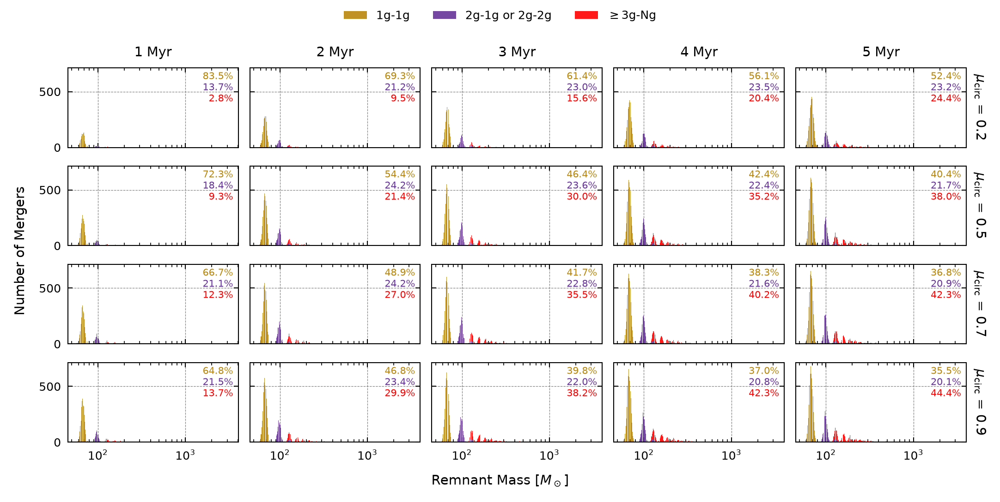

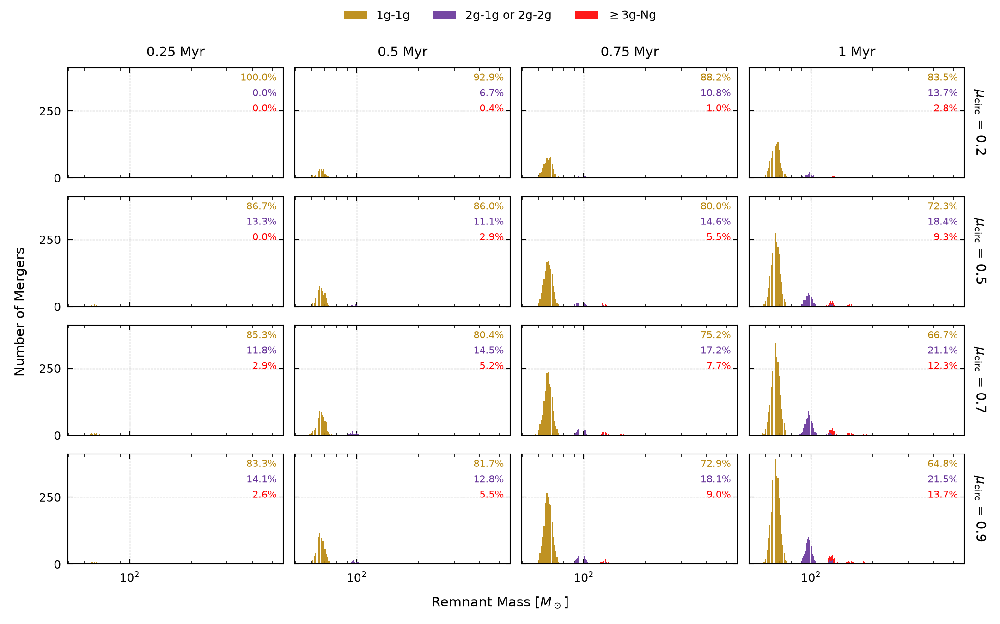

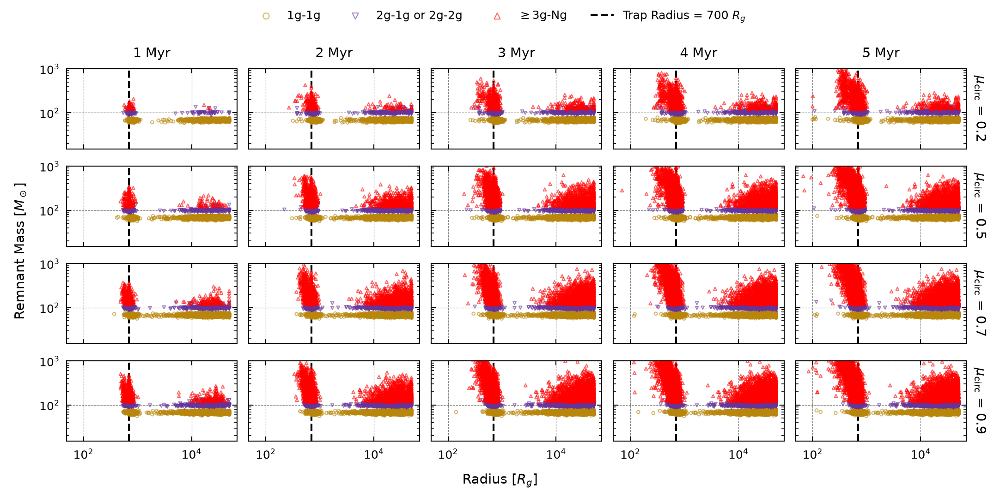

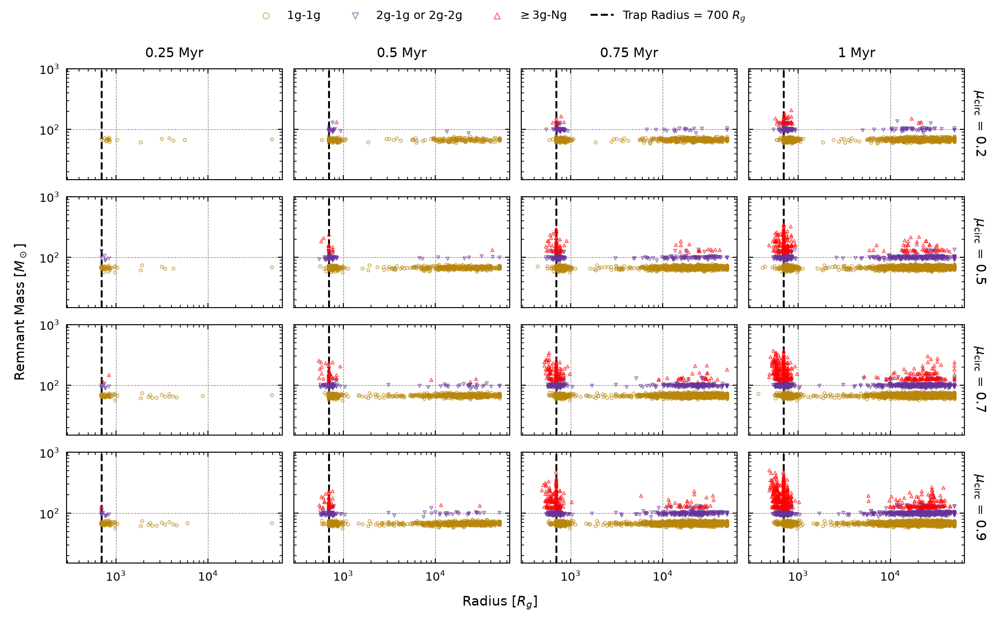

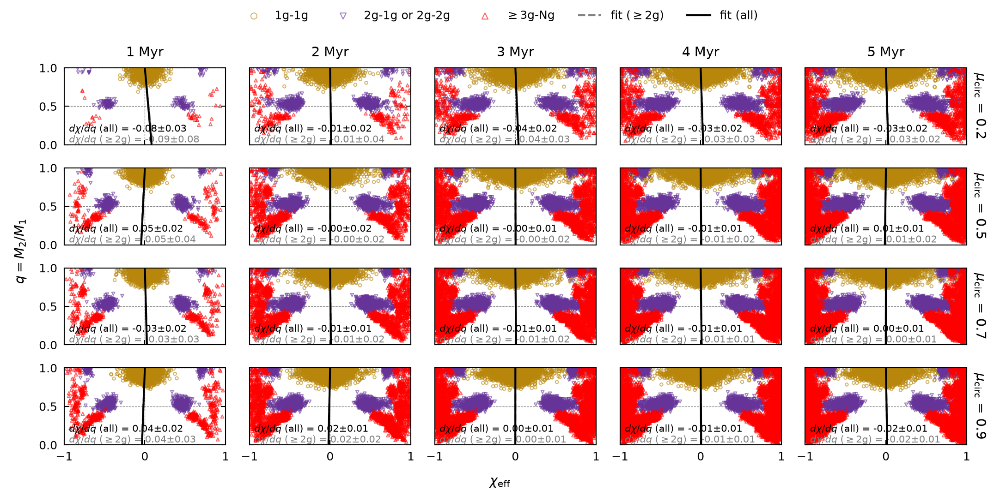

...

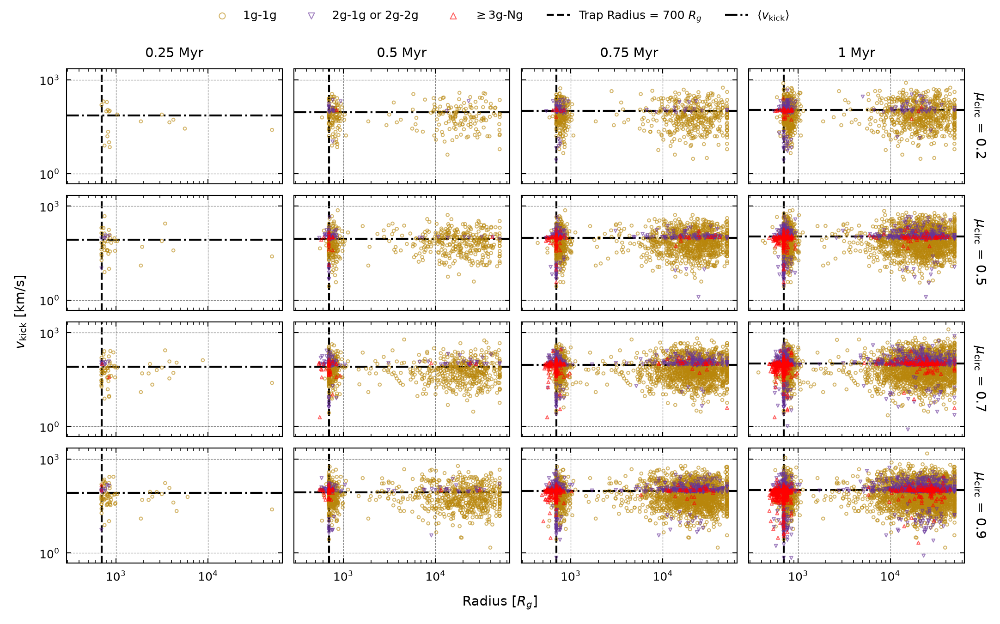

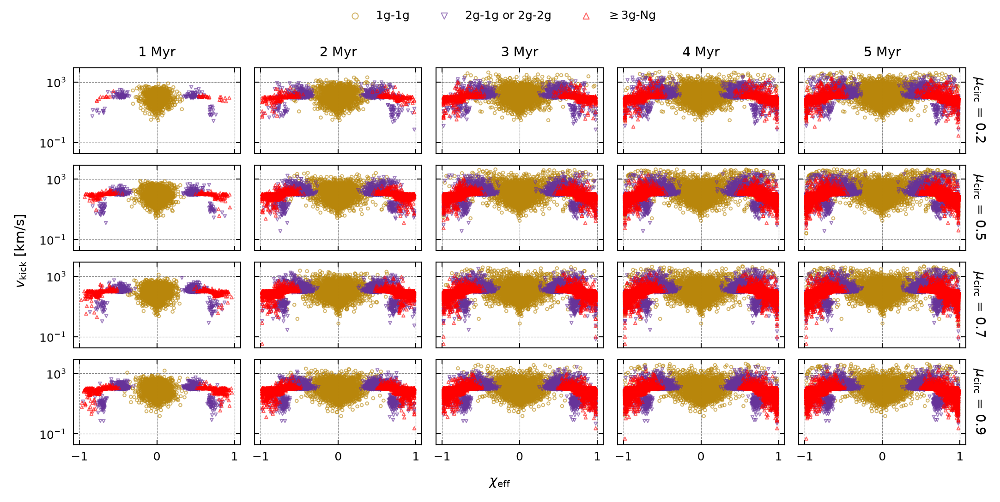

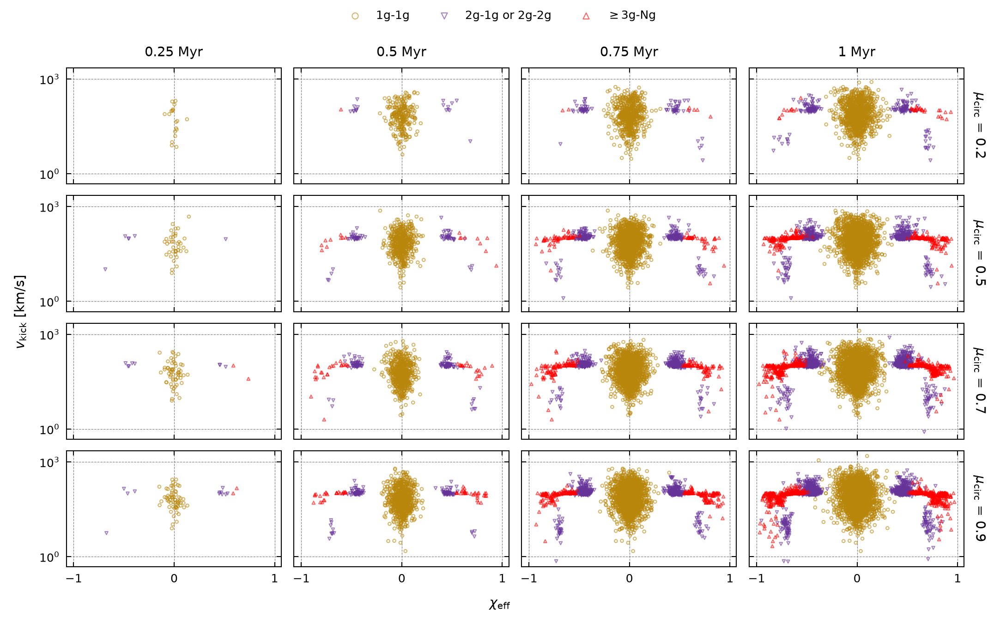

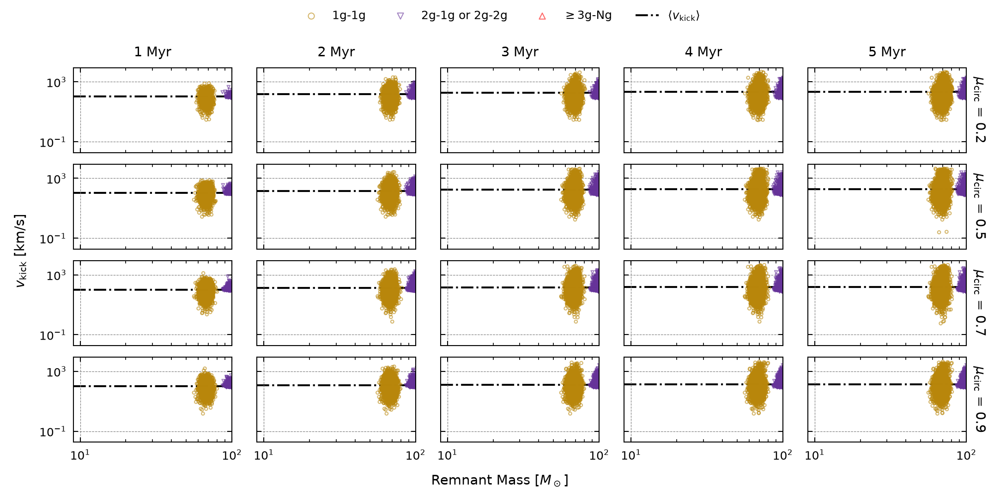

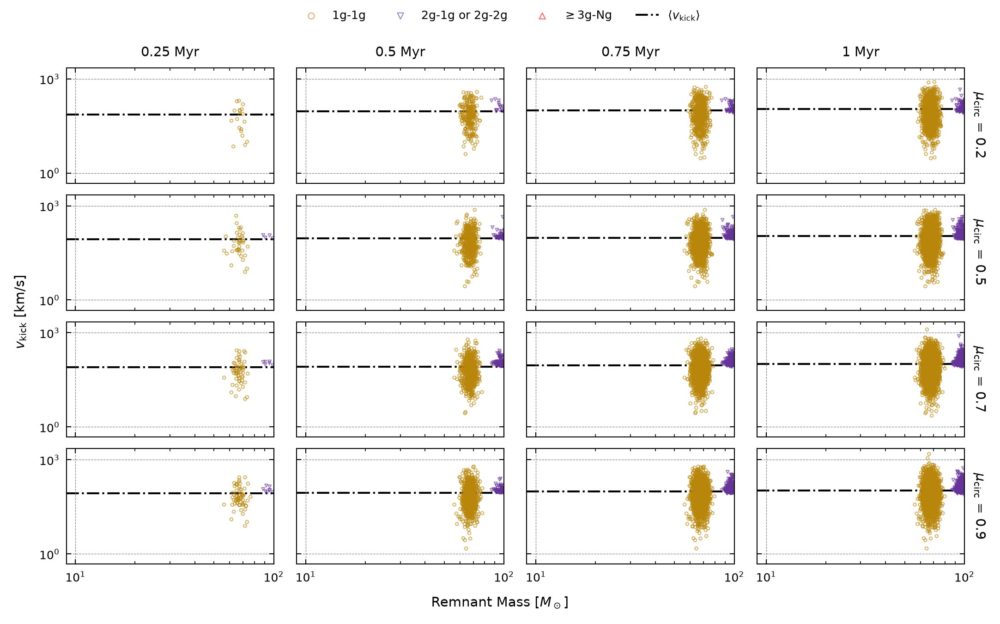

In [23]:
for (name, (draw, required_array)), (suffix, checkpoints) in itertools.product(PLOTS.items(), GRID_COLUMNS.items()):
    fig = plot_grid(draw, required_array, checkpoints)
    #save_figure(fig, name + suffix)
    plt.show()
    plt.close(fig)

## 6. Summary

Mergers per galaxy at each checkpoint. Rows are sweep values and columns are timesteps.

In [24]:
SUMMARY = pd.DataFrame(
    [
        {
            SWEEP_PARAM: value,
            "timestep": t,
            "mergers_per_galaxy": len(cabinet.get_array("blackholes_merged")) / CONFIGS[value].galaxy_num
            if "blackholes_merged" in cabinet else 0.0,
        }
        for (value, t), cabinet in RESULTS.items()
    ]
).pivot(index=SWEEP_PARAM, columns="timestep", values="mergers_per_galaxy")

os.makedirs(FIG_DIR, exist_ok=True)
SUMMARY.to_csv(os.path.join(FIG_DIR, "summary_mergers_per_galaxy.csv"))
SUMMARY

timestep,25,50,75,100,200,300,400,500
mu_circ_encounter,,,,,,,,
0.2,0.19,2.68,7.04,12.93,33.50,50.59,64.38,75.75
0.5,0.45,6.21,17.04,29.10,68.51,96.18,114.78,127.91
0.7,0.68,8.30,22.67,38.28,86.56,114.97,133.28,145.56
0.9,0.78,9.93,27.31,45.29,95.73,123.51,140.12,152.17
